<a href="https://colab.research.google.com/github/syayalaherrera-beep/Reinforcement-Learning/blob/main/Reinforcement_Learning_Qlearning_Sandra_Yurani_Ayala_Herrera.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Semana 14 – Reinforcement Learning: agente inteligente para encontrar la mejor ruta
Estudiante: Sandra Yurani Ayala Herrera
Institución: Universidad de Cundinamarca
Asignatura: Introducción a Machine Learning
Modalidad: Individual
Algoritmo: Q-Learning tabular

**Problema**
Un agente debe aprender a desplazarse desde una posición inicial hasta una meta en una cuadrícula, evitando obstáculos. No recibe una ruta correcta: aprende mediante episodios de interacción con el entorno y señales de recompensa.

**Componentes del modelo**
- Agente: entidad que selecciona movimientos.
- Entorno: cuadrícula de 5 × 5.
- Estado: coordenada (fila, columna), con 25 estados posibles.
- Acciones: arriba, abajo, izquierda y derecha.
- Recompensa: +100 al llegar a la meta; −1 por movimiento válido; −10 al intentar entrar en un obstáculo; −5 al intentar salir de los límites.
- Política: regla aprendida que relaciona cada estado con una acción.
- Episodio: secuencia de interacciones desde el inicio hasta la meta o hasta alcanzar el límite de pasos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
ROWS, COLS = 5, 5
START = (0, 0)
GOAL = (4, 4)
OBSTACLES = {(0, 3), (1, 1), (1, 3), (2, 1), (3, 2), (3, 4)}

ACTIONS = ["arriba", "abajo", "izquierda", "derecha"]
DELTAS = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def state_id(state):
    """Convierte una coordenada (fila, columna) en índice de la Q-Table."""
    return state[0] * COLS + state[1]

def step_env(state, action_idx):
    """Ejecuta una acción y devuelve siguiente estado, recompensa y fin."""
    dr, dc = DELTAS[action_idx]
    nxt = (state[0] + dr, state[1] + dc)

    if not (0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS):
        return state, -5.0, False
    if nxt in OBSTACLES:
        return state, -10.0, False
    if nxt == GOAL:
        return nxt, 100.0, True
    return nxt, -1.0, False

print("Estados:", ROWS * COLS)
print("Acciones:", ACTIONS)
print("Inicio:", START, "| Meta:", GOAL)
print("Obstáculos:", sorted(OBSTACLES))

Estados: 25
Acciones: ['arriba', 'abajo', 'izquierda', 'derecha']
Inicio: (0, 0) | Meta: (4, 4)
Obstáculos: [(0, 3), (1, 1), (1, 3), (2, 1), (3, 2), (3, 4)]


**Visualización del entorno**

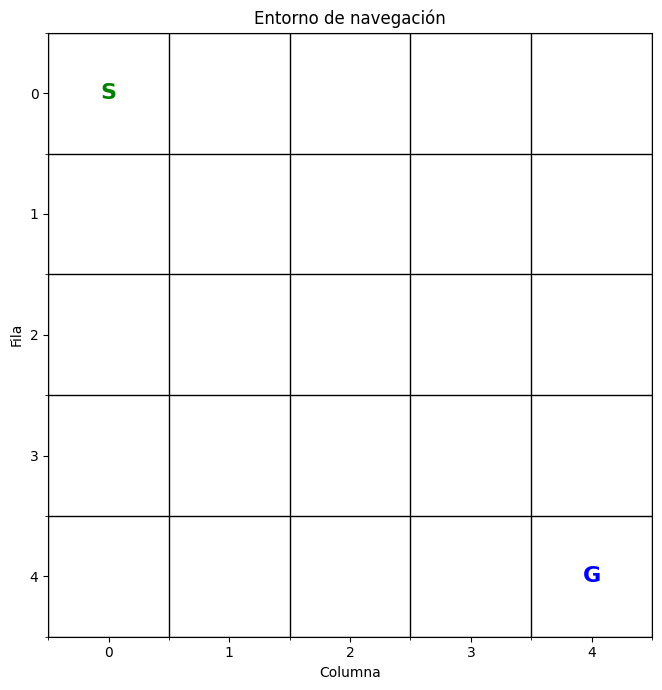

In [3]:
def plot_grid(path=None, title="Entorno de navegación"):
    """Dibuja inicio, meta, obstáculos y una ruta opcional."""
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(np.zeros((ROWS, COLS)), cmap="Greys", vmin=0, vmax=2)

    for r, c in OBSTACLES:
        ax.text(c, r, "X", ha="center", va="center",
                color="white", fontsize=16, fontweight="bold")
    ax.text(START[1], START[0], "S", ha="center", va="center",
            color="green", fontsize=16, fontweight="bold")
    ax.text(GOAL[1], GOAL[0], "G", ha="center", va="center",
            color="blue", fontsize=16, fontweight="bold")

    if path:
        ax.plot([p[1] for p in path], [p[0] for p in path],
                marker="o", linewidth=2, label="Ruta aprendida")
        ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks(np.arange(-.5, COLS, 1), minor=True)
    ax.set_yticks(np.arange(-.5, ROWS, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=1)
    ax.set_xlabel("Columna"); ax.set_ylabel("Fila")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

plot_grid()

**Algoritmo y parámetros**

Q-Learning estima el valor de ejecutar una acción en un estado mediante una tabla Q(s,a). La actualización es:
\[
Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma \max_{a'} Q(s',a') - Q(s,a)]
\]
Si se alcanza la meta, el objetivo de actualización es la recompensa terminal. Se utiliza una política ε-greedy: con probabilidad ε se explora una acción aleatoria y, en caso contrario, se selecciona una acción con mayor valor Q.

In [4]:
ALPHA = 0.1
GAMMA = 0.95
EPSILON = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.995
EPISODES = 3000
MAX_STEPS = 100

Q = np.zeros((ROWS * COLS, len(ACTIONS)), dtype=float)
print("Dimensiones de la Q-Table:", Q.shape)

Dimensiones de la Q-Table: (25, 4)


**Entrenamiento del agente**

In [5]:
episode_returns = []
episode_steps = []
episode_success = []
epsilon_history = []
epsilon = EPSILON

for episode in range(EPISODES):
    state = START
    total_reward = 0.0
    success = False

    for step in range(1, MAX_STEPS + 1):
        sid = state_id(state)

        # Selección epsilon-greedy
        if rng.random() < epsilon:
            action = int(rng.integers(len(ACTIONS)))
        else:
            best_actions = np.flatnonzero(np.isclose(Q[sid], Q[sid].max()))
            action = int(rng.choice(best_actions))

        next_state, reward, done = step_env(state, action)
        next_id = state_id(next_state)

        # Actualización de Q-Learning
        target = reward if done else reward + GAMMA * np.max(Q[next_id])
        Q[sid, action] += ALPHA * (target - Q[sid, action])

        state = next_state
        total_reward += reward
        if done:
            success = True
            break

    episode_returns.append(total_reward)
    episode_steps.append(step)
    episode_success.append(int(success))
    epsilon_history.append(epsilon)
    epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)

print("Entrenamiento finalizado:", EPISODES, "episodios")
print("Epsilon final:", round(epsilon, 4))

Entrenamiento finalizado: 3000 episodios
Epsilon final: 0.01


**Evaluación del entrenamiento**

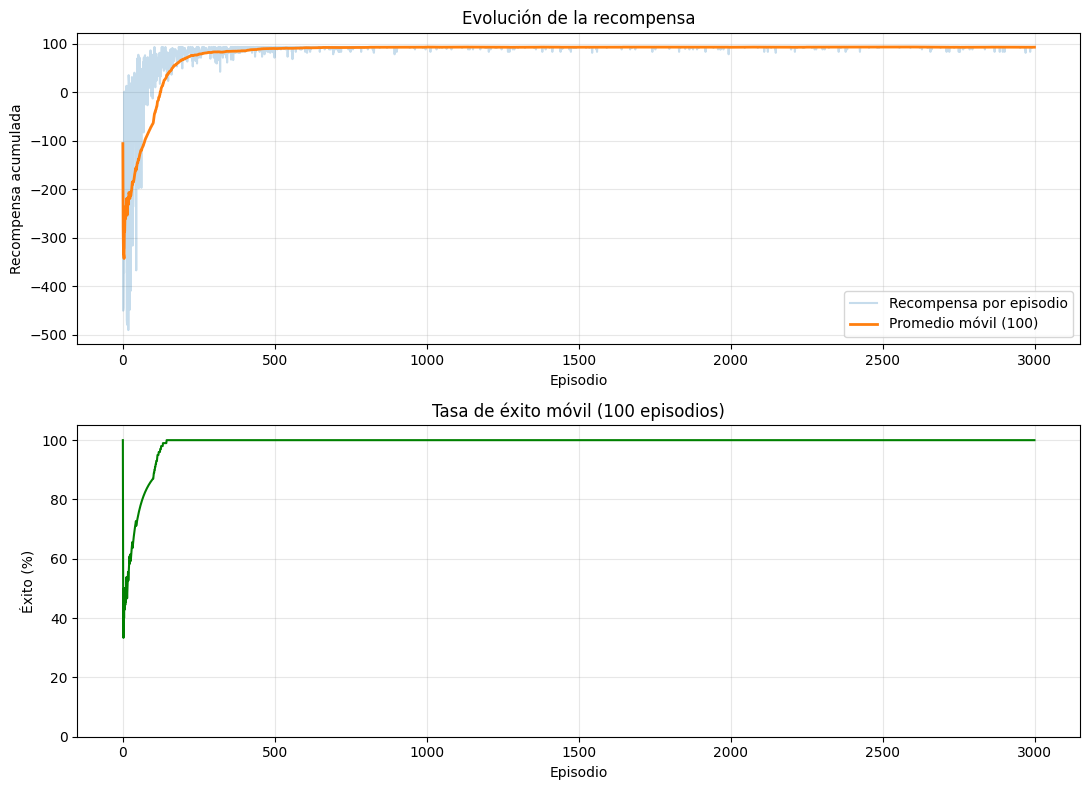

Éxito últimos 100 episodios: 100.0 %
Recompensa media últimos 100 episodios: 92.59
Pasos medios últimos 100 episodios: 8.11


In [6]:
window = 100
rewards_smooth = pd.Series(episode_returns).rolling(window, min_periods=1).mean()
success_smooth = pd.Series(episode_success).rolling(window, min_periods=1).mean() * 100

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
axes[0].plot(episode_returns, alpha=0.25, label="Recompensa por episodio")
axes[0].plot(rewards_smooth, linewidth=2, label="Promedio móvil (100)")
axes[0].set_title("Evolución de la recompensa")
axes[0].set_xlabel("Episodio"); axes[0].set_ylabel("Recompensa acumulada")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(success_smooth, color="green")
axes[1].set_title("Tasa de éxito móvil (100 episodios)")
axes[1].set_xlabel("Episodio"); axes[1].set_ylabel("Éxito (%)")
axes[1].set_ylim(0, 105); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Éxito últimos 100 episodios:",
      round(np.mean(episode_success[-100:]) * 100, 2), "%")
print("Recompensa media últimos 100 episodios:",
      round(np.mean(episode_returns[-100:]), 2))
print("Pasos medios últimos 100 episodios:",
      round(np.mean(episode_steps[-100:]), 2))

**Política aprendida y ruta final**

¿Alcanzó la meta?: True
Movimientos: 8
Recompensa de la ruta: 93.0
Ruta: [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (4, 1), (4, 2), (4, 3), (4, 4)]


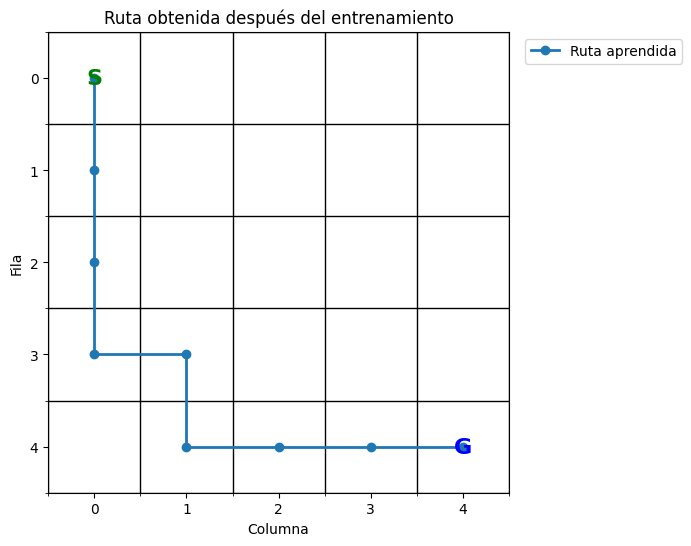

In [7]:
def greedy_route():
    """Obtiene una ruta usando valores Q y evita ciclos cuando es posible."""
    state = START
    path = [state]
    total_reward = 0.0
    visited = {state}

    for _ in range(MAX_STEPS):
        candidates = []
        for action in range(len(ACTIONS)):
            nxt, reward, done = step_env(state, action)
            if nxt != state or done:
                candidates.append((Q[state_id(state), action],
                                   action, nxt, reward, done))
        if not candidates:
            return path, total_reward, False

        candidates.sort(key=lambda item: item[0], reverse=True)
        selected = next((item for item in candidates
                         if item[2] not in visited or item[4]), candidates[0])
        _, action, nxt, reward, done = selected
        state = nxt
        path.append(state)
        visited.add(state)
        total_reward += reward
        if done:
            return path, total_reward, True

    return path, total_reward, False

final_path, final_return, reached_goal = greedy_route()
print("¿Alcanzó la meta?:", reached_goal)
print("Movimientos:", len(final_path) - 1)
print("Recompensa de la ruta:", final_return)
print("Ruta:", final_path)
plot_grid(final_path, "Ruta obtenida después del entrenamiento")

**Interpretación y limitaciones**


Después de ejecutar el proceso de entrenamiento mediante el algoritmo Q-Learning, el agente logró identificar una ruta que conecta la posición inicial (0, 0) con la posición objetivo (4, 4), evitando las celdas definidas como obstáculos.

La ruta obtenida fue: (0, 0) → (1, 0) → (2, 0) → (3, 0) → (3, 1) → (4, 1) → (4, 2) → (4, 3) → (4, 4). El recorrido requirió ocho movimientos y alcanzó una recompensa acumulada de 93 puntos.

Este resultado evidencia que el agente aprendió una política de navegación que permite alcanzar el objetivo mediante una trayectoria eficiente. La longitud de la ruta coincide con la distancia mínima posible entre las posiciones inicial y final, considerando los movimientos ortogonales permitidos. Asimismo, el agente evitó los obstáculos establecidos en el entorno.

La recompensa obtenida es consistente con el sistema definido: 100 puntos por alcanzar la meta y una penalización de un punto por cada uno de los siete movimientos intermedios. En consecuencia, el resultado demuestra que la interacción repetida con el entorno y la actualización de los valores de la Q-Table permitieron al agente aprender una secuencia de acciones adecuada para resolver el problema planteado.